# Laboratorio · Ajuste de curvas y bondad de ajuste (5.3)
**Simulación Computacional – Unillanos** · guía FO-DOC-112

Notebook independiente para el ajuste de distribuciones, como pide la guía. Usa como referencia el tutorial de
Amat Rodrigo (2021), *Ajuste y selección de distribuciones con Python*. El análisis descriptivo y de supuestos (5.1 y 5.2)
está en `Lab_Input_Data_Analysis.ipynb`.

## 0. Librerías y datos

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

IMG = Path('imagenes'); TAB = Path('tablas')        # salidas que usa el informe (main.tex)
IMG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)

In [2]:
DATA_DIR = Path.cwd()
dataset_paths = {k: DATA_DIR / f'dataset-{k}.txt' for k in 'ABCD'}
missing = [str(path) for path in dataset_paths.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(f'No se encontraron los datasets: {", ".join(missing)}')

data = {k: np.loadtxt(path) for k, path in dataset_paths.items()}
for k, x in data.items():
    print(k, len(x), x[:5])

A 200 [0.02096387 0.08135139 0.15621898 0.14936908 0.19343316]
B 200 [0.15208743 0.03557552 0.80398992 0.00727986 0.03515142]
C 200 [ 1.61591162  0.92668079  1.16692015 16.67646195 19.67795514]
D 200 [0.46374712 0.21354032 8.45622774 8.12966888 1.36584955]


## Distribuciones y criterios

Se ajustan las 5 distribuciones obligatorias (Exponencial, Lognormal, Normal, Gamma, Beta) y 4 adicionales
(Weibull, Log-logística, Rayleigh y Gaussiana inversa), todas por **máxima verosimilitud** (`scipy.stats.<dist>.fit`).

Criterios:
- **SSE** = Σ (densidad del histograma − pdf ajustada en el centro de cada bin)². Depende de los bins (aquí 20) y de la escala
  de la variable, así que solo compara distribuciones **dentro** de un mismo dataset.
- **AIC** = 2k − 2 ln L
- **BIC** = k ln n − 2 ln L  (penaliza más los parámetros que el AIC cuando n ≥ 8)

con L la verosimilitud de los datos con los parámetros MLE y k el número de parámetros **libres** estimados.
En los tres, **menor es mejor**.

Decisión de modelado (paso 1 de la estrategia de Banks: usar los límites físicos de la variable):
los datos son tiempos ≥ 0, así que para las distribuciones no negativas se fija `loc = 0` (`floc=0`).
La Beta se ajusta sobre el rango observado (soporte acotado [mín, máx], fijado un poco más ancho); como ese soporte
sale de los datos, en rigor tendría 4 parámetros, y contarlo así solo empeoraría su AIC/BIC.

Ranking combinado: promedio de los puestos en SSE, AIC y BIC; los empates se rompen con el AIC.

In [3]:
DISTS = {
    'Exponencial': 'expon',
    'Lognormal': 'lognorm',
    'Normal': 'norm',
    'Gamma': 'gamma',
    'Beta': 'beta',
    # cuatro adicionales
    'Weibull': 'weibull_min',
    'Log-logística': 'fisk',
    'Rayleigh': 'rayleigh',
    'Gaussiana inversa': 'invgauss',
}

def ajustar(x, nombre, scipy_name, bins=20):
    dist = getattr(st, scipy_name)
    n = len(x)
    if scipy_name == 'norm':
        params = dist.fit(x); k = 2
    elif scipy_name == 'beta':
        eps = 1e-6 * (x.max() - x.min())
        params = dist.fit(x, floc=x.min() - eps, fscale=(x.max() - x.min()) + 2 * eps); k = 2
    else:
        params = dist.fit(x, floc=0)
        k = len(params) - 1                       # loc fijo, no cuenta
    logL = np.sum(dist.logpdf(x, *params))
    dens, edges = np.histogram(x, bins=bins, density=True)
    centros = (edges[:-1] + edges[1:]) / 2
    sse = np.sum((dens - dist.pdf(centros, *params)) ** 2)
    nombres_par = (dist.shapes.split(', ') if dist.shapes else []) + ['loc', 'scale']
    ptxt = ', '.join(f'{p}={v:.4g}' for p, v in zip(nombres_par, params))
    return {'Distribución': nombre, 'scipy': scipy_name, 'Parámetros': ptxt, 'params': params,
            'k': k, 'logL': logL, 'SSE': sse, 'AIC': 2 * k - 2 * logL, 'BIC': k * np.log(n) - 2 * logL}

def tabla_ajuste(x):
    df = pd.DataFrame([ajustar(x, nom, sn) for nom, sn in DISTS.items()])
    df['rank_prom'] = df[['SSE', 'AIC', 'BIC']].rank().mean(axis=1)
    return df.sort_values(['rank_prom', 'AIC'], kind='stable').reset_index(drop=True)

def mostrar(df):
    return df[['Distribución', 'Parámetros', 'SSE', 'AIC', 'BIC', 'rank_prom']].style.format(
        {'SSE': '{:.4g}', 'AIC': '{:.2f}', 'BIC': '{:.2f}', 'rank_prom': '{:.2f}'})

def graficar_top3(k, x, df):
    fig, ax = plt.subplots(figsize=(8, 5))
    dens, _, _ = ax.hist(x, bins=20, density=True, alpha=0.4, edgecolor='black', label='datos')
    xs = np.linspace(x.min(), x.max(), 400)
    for (_, r), ls in zip(df.head(3).iterrows(), ['-', '--', ':']):
        ax.plot(xs, getattr(st, r['scipy']).pdf(xs, *r['params']), lw=2, ls=ls,
                label=f"{r['Distribución']} (AIC={r['AIC']:.1f})")
    ax.set_ylim(0, 1.3 * dens.max())          # las pdf con forma < 1 divergen en 0
    ax.set_title(f'Dataset {k}: histograma y 3 mejores ajustes'); ax.legend()
    fig.savefig(IMG / f'top3_{k}.png', bbox_inches='tight'); plt.show()

PAR_TEX = {'a': 'a', 'b': 'b', 'c': 'c', 's': '\\sigma', 'mu': '\\mu', 'loc': '\\text{loc}', 'scale': '\\text{escala}'}
def num_tex(v, cifras=4):
    # número en formato LaTeX con coma decimal (estilo del informe)
    if isinstance(v, (int, np.integer)) or float(v).is_integer() and abs(v) < 1e6:
        return f'${int(v)}$'
    s = f'{v:.{cifras}g}'
    if 'e' in s:
        m, e = s.split('e')
        return f'${m.replace(".", "{,}")}\\times10^{{{int(e)}}}$'
    return f'${s.replace(".", "{,}")}$'

def exportar_tabla(k, df):
    # filas en el orden de la guía; se marca en negrita el mejor valor de cada criterio
    dist_par = {sn: getattr(st, sn) for sn in DISTS.values()}
    mejores = {c: df[c].min() for c in ['SSE', 'AIC', 'BIC']}
    with open(TAB / f'tabla_ajuste_{k}.tex', 'w', encoding='utf-8') as f:
        for nombre in DISTS:
            r = df[df['Distribución'] == nombre].iloc[0]
            d = dist_par[r['scipy']]
            nombres_par = (d.shapes.split(', ') if d.shapes else []) + ['loc', 'scale']
            # loc solo se muestra cuando se estimó o no es 0
            par = ', '.join(f'${PAR_TEX[p]}={num_tex(v, 4)[1:-1]}$' for p, v in zip(nombres_par, r['params'])
                            if not (p == 'loc' and v == 0))
            celdas = []
            for c in ['SSE', 'AIC', 'BIC']:
                t = num_tex(r[c], 4) if c == 'SSE' else f"${r[c]:.2f}$".replace('.', '{,}')
                celdas.append(f'$\\mathbf{{{t[1:-1]}}}$' if r[c] == mejores[c] else t)
            puesto = int(df.index[df['Distribución'] == nombre][0]) + 1
            f.write(f'{nombre} & {par} & ' + ' & '.join(celdas) + f' & {puesto} \\\\\n')

resultados = {}

### Tabla de bondad de ajuste – Dataset A

In [4]:
resultados['A'] = tabla_ajuste(data['A'])
exportar_tabla('A', resultados['A'])
mostrar(resultados['A'])

,Distribución,Parámetros,SSE,AIC,BIC,rank_prom
0,Normal,"loc=0.195, scale=0.0437",29.15,-680.59,-673.99,1.33
1,Weibull,"c=5.071, loc=0, scale=0.212",32.43,-679.36,-672.76,2.33
2,Gamma,"a=16.18, loc=0, scale=0.01206",28.24,-647.34,-640.75,3.00
3,Log-logística,"c=7.293, loc=0, scale=0.1927",33.42,-655.44,-648.85,3.33
4,Lognormal,"s=0.275, loc=0, scale=0.189",36.97,-611.09,-604.49,5.00
5,Beta,"a=2.862, b=1.798, loc=0.02096, scale=0.278",59.26,-597.26,-590.66,6.33
6,Gaussiana inversa,"mu=0.08962, loc=0, scale=2.176",48.06,-583.42,-576.83,6.67
7,Rayleigh,"loc=0, scale=0.1413",185.2,-497.00,-493.70,8.00
8,Exponencial,"loc=0, scale=0.195",340.5,-251.82,-248.52,9.00


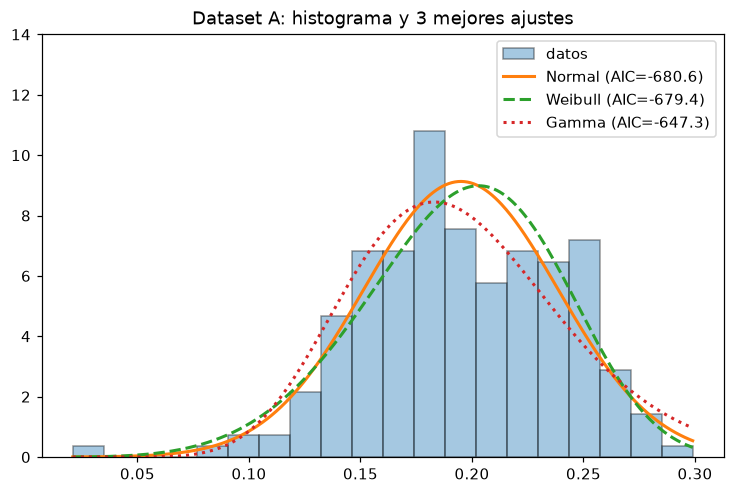

In [5]:
graficar_top3('A', data['A'], resultados['A'])

**Dataset A.** La Normal gana en AIC y BIC (−680,59 / −673,99), con la Weibull (c = 5,07) muy cerca (ΔAIC = 1,2).
La Gamma tiene el menor SSE, pero su AIC es 33 puntos peor. La Exponencial y la Rayleigh quedan últimas porque no pueden
representar una campana alejada de cero. La Normal solo da probabilidad 4·10⁻⁶ a valores negativos, así que no viola el límite físico
en la práctica. **Top 3: Normal, Weibull y Gamma.**

### Tabla de bondad de ajuste – Dataset B

In [6]:
resultados['B'] = tabla_ajuste(data['B'])
exportar_tabla('B', resultados['B'])
mostrar(resultados['B'])

,Distribución,Parámetros,SSE,AIC,BIC,rank_prom
0,Weibull,"c=0.9095, loc=0, scale=0.1963",0.2762,-232.26,-225.67,1.33
1,Gamma,"a=0.8636, loc=0, scale=0.2378",0.3158,-232.10,-225.50,2.33
2,Exponencial,"loc=0, scale=0.2054",0.4358,-231.13,-227.83,2.33
3,Log-logística,"c=1.307, loc=0, scale=0.1184",1.143,-206.65,-200.06,4.00
4,Lognormal,"s=1.437, loc=0, scale=0.104",2.326,-188.73,-182.14,5.00
5,Beta,"a=0.5585, b=2.72, loc=8.361e-05, scale=1.551",2.534,-169.24,-162.64,6.00
6,Normal,"loc=0.2054, scale=0.2285",11.57,-18.89,-12.29,7.33
7,Rayleigh,"loc=0, scale=0.2173",18.12,85.99,89.29,8.33
8,Gaussiana inversa,"mu=22.4, loc=0, scale=0.009169",6.528,151.99,158.58,8.33


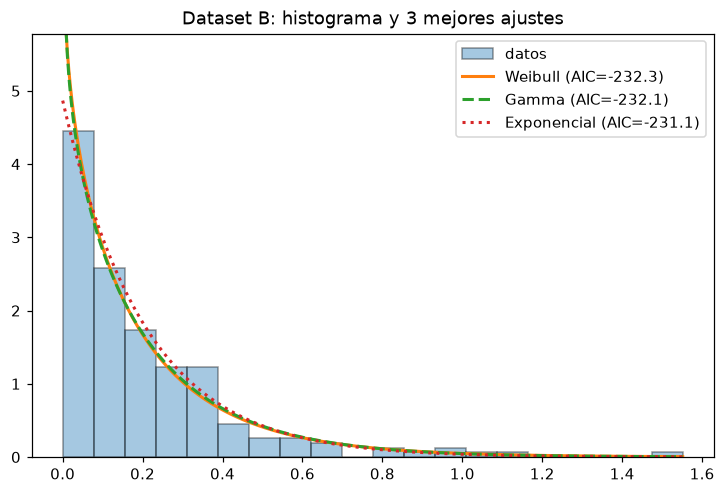

In [7]:
graficar_top3('B', data['B'], resultados['B'])

**Dataset B.** Los tres primeros son la Weibull (c = 0,91), la Gamma (a = 0,86) y la Exponencial (media 0,205), con AIC
en un rango de 1,1 puntos. La Weibull tiene el menor SSE y AIC; la Exponencial, el menor BIC, porque usa un parámetro menos.
Las dos formas estimadas están cerca de 1, que es justo el caso en que Weibull y Gamma se reducen a la Exponencial.
**Top 3: Weibull, Gamma y Exponencial.**

### Tabla de bondad de ajuste – Dataset C

In [8]:
resultados['C'] = tabla_ajuste(data['C'])
exportar_tabla('C', resultados['C'])
mostrar(resultados['C'])

,Distribución,Parámetros,SSE,AIC,BIC,rank_prom
0,Gamma,"a=0.7062, loc=0, scale=1080",4.493e-08,3040.22,3046.82,1.67
1,Weibull,"c=0.8007, loc=0, scale=676",2.524e-08,3040.81,3047.41,1.67
2,Exponencial,"loc=0, scale=762.4",5.978e-08,3056.59,3059.88,3.33
3,Log-logística,"c=1.126, loc=0, scale=384.4",4.076e-08,3072.48,3079.08,3.33
4,Lognormal,"s=1.648, loc=0, scale=324.3",6.361e-08,3084.19,3090.78,5.00
5,Beta,"a=0.4714, b=2.635, loc=0.92, scale=6669",2.538e-07,3092.86,3099.45,6.00
6,Normal,"loc=762.4, scale=920.8",9.265e-07,3301.68,3308.28,7.33
7,Gaussiana inversa,"mu=19.81, loc=0, scale=38.49",3.224e-07,3310.51,3317.11,7.67
8,Rayleigh,"loc=0, scale=845.3",1.434e-06,3481.09,3484.39,9.00


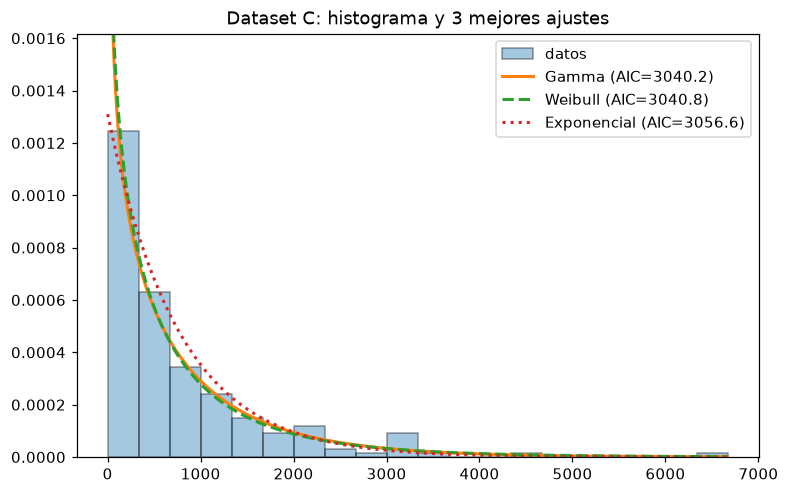

In [9]:
graficar_top3('C', data['C'], resultados['C'])

**Dataset C.** La Gamma (a = 0,71) y la Weibull (c = 0,80) empatan en el ranking (ΔAIC = 0,6), y la Exponencial es tercera
(ΔAIC = 16). Las formas < 1 indican más variabilidad que la exponencial (CV 1,21). Este exceso se explica por la no estacionariedad
encontrada en 5.2: mezclar exponenciales con medias distintas produce una distribución con CV > 1. Nota: el SSE es del orden de 10⁻⁸
porque la densidad de una variable con escala de miles es muy pequeña; por eso el SSE solo compara dentro de un mismo dataset.
**Top 3: Gamma, Weibull y Exponencial.**

### Tabla de bondad de ajuste – Dataset D

In [10]:
resultados['D'] = tabla_ajuste(data['D'])
exportar_tabla('D', resultados['D'])
mostrar(resultados['D'])

,Distribución,Parámetros,SSE,AIC,BIC,rank_prom
0,Lognormal,"s=1.019, loc=0, scale=1.273",0.006913,675.89,682.49,1.33
1,Log-logística,"c=1.705, loc=0, scale=1.31",0.006011,681.40,688.00,1.67
2,Gaussiana inversa,"mu=1.763, loc=0, scale=1.169",0.02549,685.40,692.00,4.00
3,Exponencial,"loc=0, scale=2.06",0.009898,691.18,694.48,4.00
4,Gamma,"a=1.178, loc=0, scale=1.749",0.01048,689.97,696.56,4.33
5,Weibull,"c=1.042, loc=0, scale=2.099",0.01066,692.55,699.14,5.67
6,Beta,"a=0.5489, b=3.092, loc=0.1115, scale=17.86",0.03516,755.55,762.15,7.00
7,Normal,"loc=2.06, scale=2.321",0.1175,908.33,914.93,8.00
8,Rayleigh,"loc=0, scale=2.194",0.1572,934.06,937.36,9.00


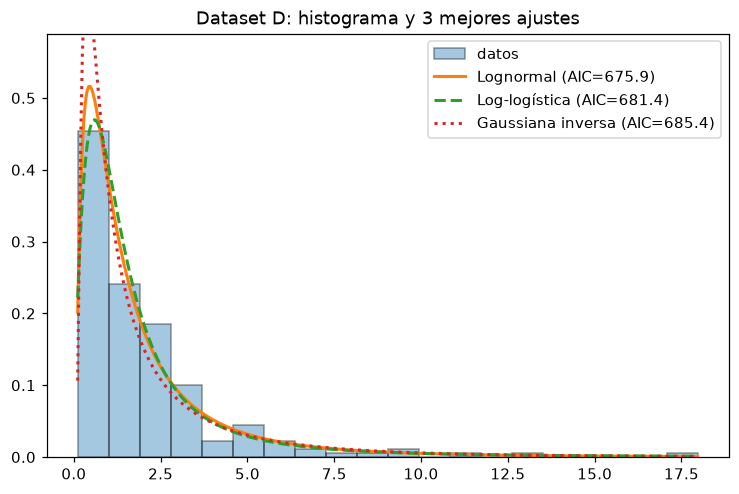

In [11]:
graficar_top3('D', data['D'], resultados['D'])

**Dataset D.** La Lognormal (σ = 1,02, escala 1,27, es decir, ln X ~ N(0,241; 1,019²)) gana en AIC y BIC. La Log-logística
tiene el menor SSE y es segunda (ΔAIC = 5,5). La Gaussiana inversa es tercera por AIC/BIC, empatada en el ranking con la Exponencial,
que tiene mejor SSE. Las tres primeras tienen moda mayor que cero y cola derecha larga, como el histograma.
**Top 3: Lognormal, Log-logística y Gaussiana inversa.**

### Comprobación: P-P, Q-Q y K-S del mejor modelo
El P-P es más sensible en el centro de la distribución; el Q-Q, en las colas.

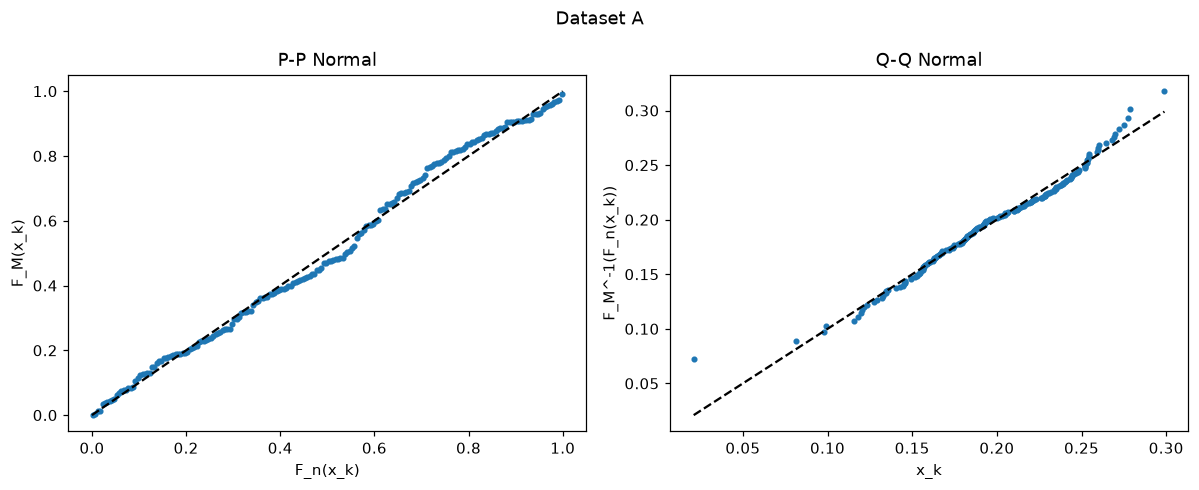

K-S: D = 0.0523, p ≈ 0.626  (p aproximado: los parámetros salieron de los mismos datos)


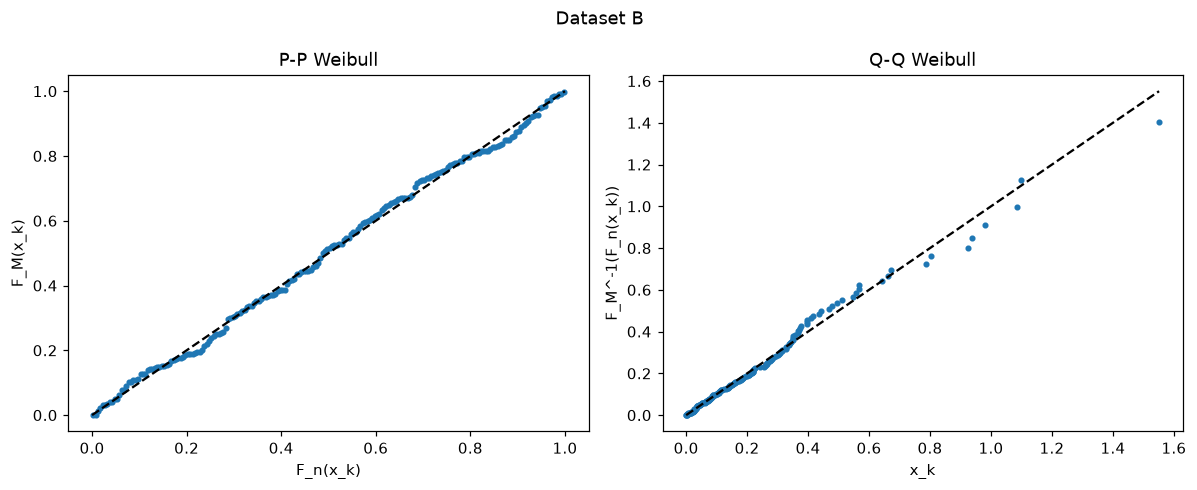

K-S: D = 0.0349, p ≈ 0.960  (p aproximado: los parámetros salieron de los mismos datos)


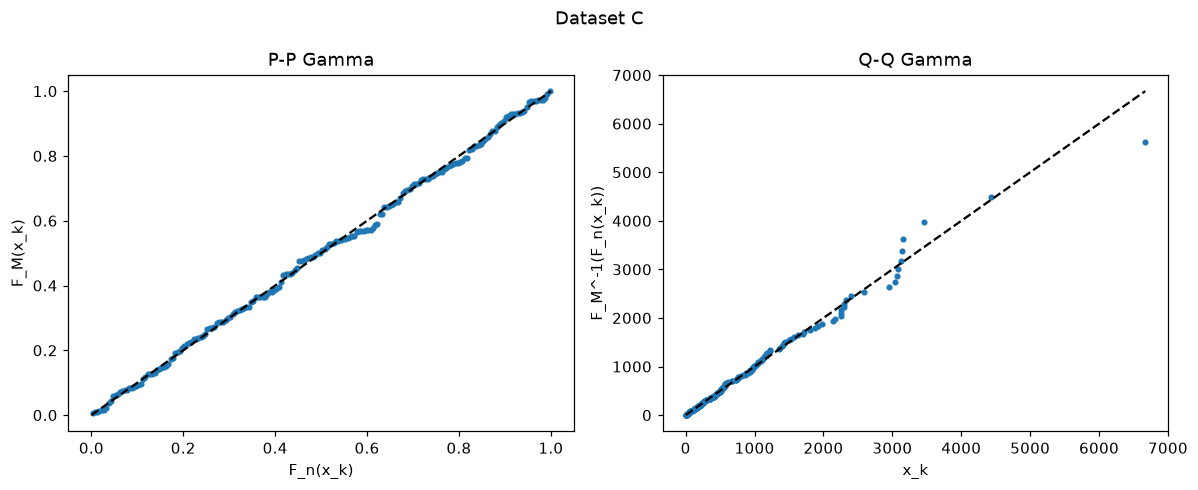

K-S: D = 0.0388, p ≈ 0.913  (p aproximado: los parámetros salieron de los mismos datos)


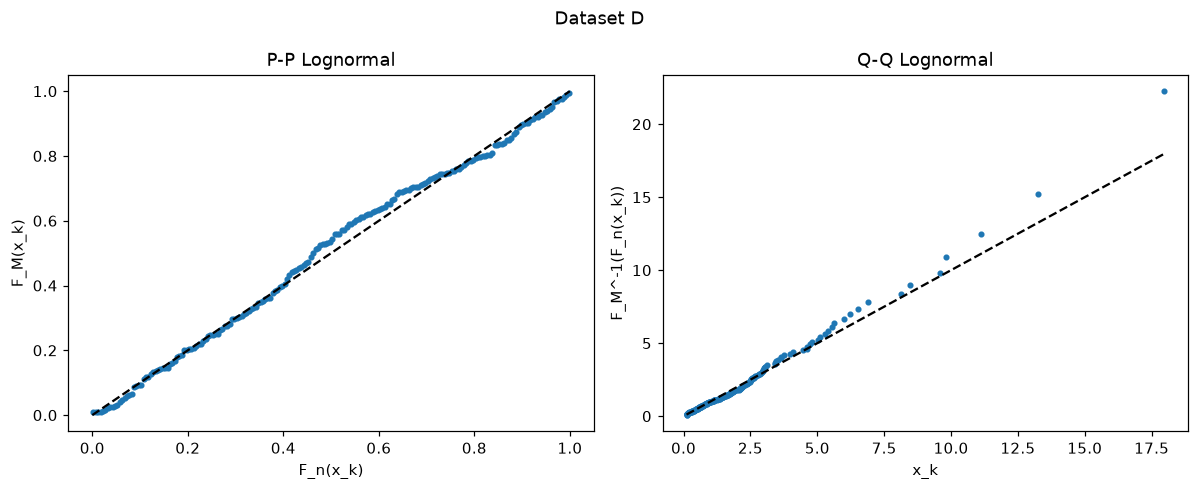

K-S: D = 0.0537, p ≈ 0.591  (p aproximado: los parámetros salieron de los mismos datos)


In [12]:
def qq_ks(k, x, df, i=0):
    r = df.iloc[i]; dist = getattr(st, r['scipy'])
    xs = np.sort(x); n = len(xs)
    Fn = (np.arange(1, n + 1) - 0.5) / n               # F_n de Banks: (N(x) - 1/2)/n
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
    axs[0].plot(Fn, dist.cdf(xs, *r['params']), '.'); axs[0].plot([0, 1], [0, 1], 'k--')
    axs[0].set_title(f"P-P {r['Distribución']}"); axs[0].set_xlabel('F_n(x_k)'); axs[0].set_ylabel('F_M(x_k)')
    axs[1].plot(xs, dist.ppf(Fn, *r['params']), '.'); axs[1].plot([xs[0], xs[-1]], [xs[0], xs[-1]], 'k--')
    axs[1].set_title(f"Q-Q {r['Distribución']}"); axs[1].set_xlabel('x_k'); axs[1].set_ylabel('F_M^-1(F_n(x_k))')
    fig.suptitle(f'Dataset {k}'); plt.tight_layout()
    fig.savefig(IMG / f'ppqq_{k}.png', bbox_inches='tight'); plt.show()
    ks = st.kstest(x, dist.cdf, args=tuple(r['params']))
    print(f"K-S: D = {ks.statistic:.4f}, p ≈ {ks.pvalue:.3f}  (p aproximado: los parámetros salieron de los mismos datos)")
    return ks

ks = {k: qq_ks(k, data[k], resultados[k], i) for k, i in [('A', 0), ('B', 0), ('C', 0), ('D', 0)]}

### Exponencial frente a Weibull y Gamma (Dataset B)
La Exponencial es el caso particular de la Weibull con c = 1 y de la Gamma con a = 1, así que la comparación se puede hacer
con la **razón de verosimilitudes**: 2(ln L₁ − ln L₀) ~ χ²(1) bajo H0 (forma = 1).

In [13]:
df = resultados['B'].set_index('Distribución')
for alt in ['Weibull', 'Gamma']:
    lr = 2 * (df.loc[alt, 'logL'] - df.loc['Exponencial', 'logL'])
    print(f'Exponencial vs {alt}: LR = {lr:.3f}, p = {st.chi2.sf(lr, 1):.3f}')

Exponencial vs Weibull: LR = 3.132, p = 0.077
Exponencial vs Gamma: LR = 2.966, p = 0.085


### Lectura de P-P, Q-Q, K-S y razón de verosimilitudes
- **A (Normal):** P-P pegado a la diagonal. En el Q-Q, el centro es muy bueno y solo se separan los extremos: el primer dato (0,021)
  queda muy por debajo del modelo (es el *warm-up*), y la cola derecha de los datos es un poco más corta que la normal. K-S p = 0,63.
- **B (Weibull):** P-P y Q-Q sobre la diagonal hasta 0,7; arriba hay pocos puntos y dispersión normal en una cola. K-S p = 0,96.
  La razón de verosimilitudes **no rechaza** que la forma sea 1: Exponencial vs Weibull p = 0,077 y vs Gamma p = 0,085.
  Agregar el parámetro de forma no mejora el ajuste de forma significativa.
- **C (Gamma):** buen ajuste aparente (K-S p = 0,91), pero eso solo dice que la distribución agregada se parece a una Gamma. No valida el
  supuesto IID, que ya falló en 5.2.
- **D (Lognormal):** P-P casi sobre la diagonal, con una pequeña S en el centro. En el Q-Q, el modelo predice valores extremos algo más
  grandes que los observados (el máximo, 18,0, corresponde a un cuantil teórico ≈ 22). K-S p = 0,59.

Los valores p de K-S son optimistas porque los parámetros se estimaron con los mismos datos. Aun así, ninguno rechaza el modelo.

### Modelos para los casos no IID (Banks, sección 3.6)
En 5.2 los datasets A y C no cumplieron el supuesto IID, así que una sola distribución univariada no basta.

- **A (correlacionado, estacionario):** proceso AR(1) $X_k = \mu + \varphi (X_{k-1} - \mu) + \varepsilon_k$, con
  $\varphi = r_1$ e innovaciones $\varepsilon_k$ IID. Se revisa si los residuos quedan sin correlación y qué distribución tienen.
- **C (no estacionario):** la media crece con el orden $k$. Se estima la tendencia lineal $m(k) = \beta_0 + \beta_1 k$ por
  mínimos cuadrados y se analiza $Z_k = X_k / m(k)$. Si $Z_k$ es IID, el modelo es $X_k = m(k)\,Z_k$.

A ~ AR(1): mu = 0.1950, phi = 0.517, sigma_eps = 0.0361
   residuos: Ljung-Box p = 0.291, curtosis = -1.24, Shapiro (normalidad) p = 1.2e-06
   innovaciones ~ U(-0.0599, 0.0613): K-S p = 0.725 | AIC uniforme = -835.8 vs normal = -754.5
C: m(k) = 10.82 + 7.553 k  (p pendiente = 1.4e-12)
   Z = X/m(k): lag1 = -0.052, Ljung-Box p = 0.295, Kruskal-Wallis 4 bloques p = 0.869, CV = 1.039
 Distribución                   Parámetros        AIC        BIC  rank_prom
  Exponencial          loc=0, scale=0.9883 397.305690 400.604008   1.666667
        Gamma a=1.033, loc=0, scale=0.9569 399.173305 405.769939   2.000000
      Weibull c=1.006, loc=0, scale=0.9908 399.294267 405.890901   2.333333
Log-logística c=1.499, loc=0, scale=0.6238 415.400255 421.996890   4.000000
   K-S Exponencial para Z: p = 0.835


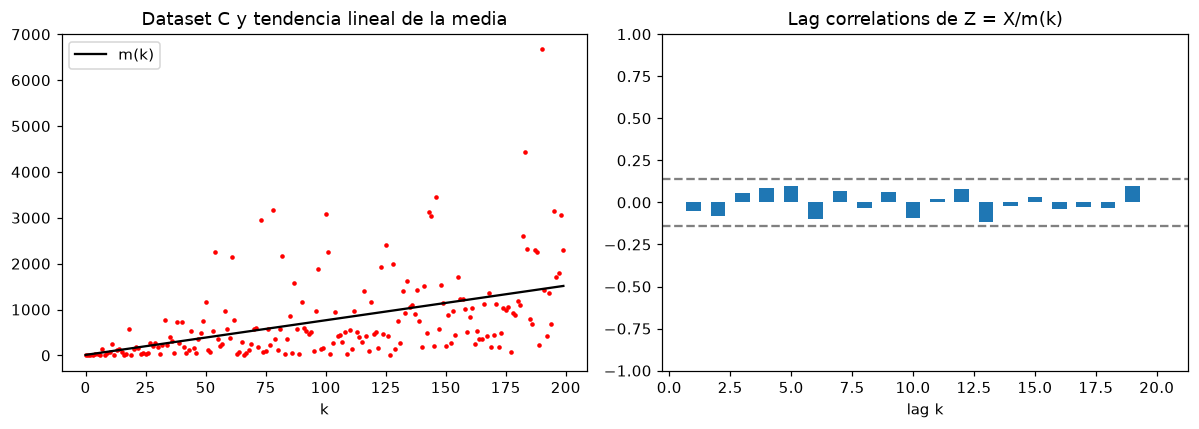

In [14]:
def ljung_box(x, m=10):
    n = len(x)
    r = [np.corrcoef(x[:-j], x[j:])[0, 1] for j in range(1, m + 1)]
    q = n * (n + 2) * sum(rj ** 2 / (n - j) for j, rj in enumerate(r, 1))
    return st.chi2.sf(q, m)

# --- A: AR(1)
x = data['A']; mu = x.mean()
phi = np.corrcoef(x[:-1], x[1:])[0, 1]
eps = (x[1:] - mu) - phi * (x[:-1] - mu)
print(f'A ~ AR(1): mu = {mu:.4f}, phi = {phi:.3f}, sigma_eps = {eps.std(ddof=1):.4f}')
print(f'   residuos: Ljung-Box p = {ljung_box(eps):.3f}, curtosis = {st.kurtosis(eps):.2f}, '
      f'Shapiro (normalidad) p = {st.shapiro(eps).pvalue:.1e}')
u_loc, u_scale = st.uniform.fit(eps)
aic_u = 4 - 2 * st.uniform.logpdf(eps, u_loc, u_scale).sum()
aic_n = 4 - 2 * st.norm.logpdf(eps, *st.norm.fit(eps)).sum()
print(f'   innovaciones ~ U({u_loc:.4f}, {u_loc + u_scale:.4f}): K-S p = '
      f'{st.kstest(eps, "uniform", args=(u_loc, u_scale)).pvalue:.3f} | AIC uniforme = {aic_u:.1f} vs normal = {aic_n:.1f}')

# --- C: tendencia lineal de la media
x = data['C']; k = np.arange(len(x))
reg = st.linregress(k, x)
z = x / (reg.intercept + reg.slope * k)
print(f'C: m(k) = {reg.intercept:.2f} + {reg.slope:.3f} k  (p pendiente = {reg.pvalue:.1e})')
print(f'   Z = X/m(k): lag1 = {np.corrcoef(z[:-1], z[1:])[0, 1]:.3f}, Ljung-Box p = {ljung_box(z):.3f}, '
      f'Kruskal-Wallis 4 bloques p = {st.kruskal(*np.array_split(z, 4)).pvalue:.3f}, CV = {z.std(ddof=1) / z.mean():.3f}')
res_z = tabla_ajuste(z)
print(res_z[['Distribución', 'Parámetros', 'AIC', 'BIC', 'rank_prom']].head(4).to_string(index=False))
print(f"   K-S Exponencial para Z: p = {st.kstest(z, 'expon', args=st.expon.fit(z, floc=0)).pvalue:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(k, x, 'r.', ms=4); axs[0].plot(k, reg.intercept + reg.slope * k, 'k-', label='m(k)')
axs[0].set_title('Dataset C y tendencia lineal de la media'); axs[0].set_xlabel('k'); axs[0].legend()
plot_lag_z = [np.corrcoef(z[:-j], z[j:])[0, 1] for j in range(1, 21)]
axs[1].bar(range(1, 21), plot_lag_z, width=0.6); b = 2 / np.sqrt(len(z))
axs[1].axhline(b, ls='--', c='gray'); axs[1].axhline(-b, ls='--', c='gray'); axs[1].set_ylim(-1, 1)
axs[1].set_title('Lag correlations de Z = X/m(k)'); axs[1].set_xlabel('lag k')
plt.tight_layout(); fig.savefig(IMG / 'tendencia_C.png', bbox_inches='tight'); plt.show()

### Interpretación de los modelos no IID
- **A:** el AR(1) con φ = 0,517 elimina la autocorrelación (Ljung-Box de los residuos p = 0,29). Los residuos **no son normales**:
  curtosis −1,24 y rango cerrado ±0,06. Su forma es **uniforme**, U(−0,060; 0,061), con K-S p = 0,73 y un AIC 81 puntos mejor que la
  normal. Por eso el modelo generador es X_k = 0,195 + 0,517 (X_{k−1} − 0,195) + U(−0,060; 0,061). La marginal resultante es una suma
  ponderada de uniformes, casi normal pero con colas cortas, lo que coincide con el Q-Q de la Normal.
- **C:** la media crece de forma lineal, m(k) = 10,82 + 7,553·k (pendiente con p ≈ 10⁻¹²). Los datos normalizados Z = X/m(k) quedan
  **IID**: lag 1 = −0,05, Ljung-Box p = 0,30, Kruskal-Wallis p = 0,87. Además, son **exponenciales**: CV = 1,04, la Exponencial gana
  en AIC/BIC y la Gamma/Weibull estimadas tienen forma ≈ 1, con K-S p = 0,84. Es decir, C son tiempos entre llegadas exponenciales
  con media creciente: un proceso de llegadas cuya tasa disminuye con el tiempo, no un proceso Gamma.

### Selección final

In [15]:
ELEGIDA = {'A': 'Normal', 'B': 'Exponencial', 'C': 'Exponencial', 'D': 'Lognormal'}
MODELO = {'A': f'AR(1): mu = {mu:.3f}, phi = {phi:.3f}, eps ~ U({u_loc:.3f}, {u_loc + u_scale:.3f})',
          'B': 'IID Exponencial',
          'C': f'X_k = m(k) Z_k, m(k) = {reg.intercept:.2f} + {reg.slope:.3f} k, Z ~ Exp(media {st.expon.fit(z, floc=0)[1]:.3f})',
          'D': 'IID Lognormal'}
sel = pd.DataFrame([{'Dataset': k, 'Distribución': d,
                     **resultados[k].set_index('Distribución').loc[d, ['Parámetros', 'AIC', 'BIC']].to_dict(),
                     'Modelo para simular': MODELO[k]} for k, d in ELEGIDA.items()]).set_index('Dataset')
sel

,Distribución,Parámetros,AIC,BIC,Modelo para simular
Dataset,,,,,
A,Normal,"loc=0.195, scale=0.0437",-680.586590,-673.989955,"AR(1): mu = 0.195, phi = 0.517, eps ~ U(-0.060..."
B,Exponencial,"loc=0, scale=0.2054",-231.131459,-227.833142,IID Exponencial
C,Exponencial,"loc=0, scale=762.4",3056.585307,3059.883625,"X_k = m(k) Z_k, m(k) = 10.82 + 7.553 k, Z ~ Ex..."
D,Lognormal,"s=1.019, loc=0, scale=1.273",675.892707,682.489342,IID Lognormal


### ¿Cuál de las tres distribuciones se selecciona por conjunto de datos?
- **A → Normal(μ = 0,195; σ = 0,0437)** para la marginal. Gana en AIC y BIC, respeta el rango observado en la práctica y su Q-Q es muy
  bueno en el centro. La Weibull es casi equivalente (ΔAIC = 1,2), pero la Normal es más simple de interpretar y es coherente con la
  marginal de un AR(1). Como A está correlacionado, **en la simulación no deben generarse valores independientes**: hay que usar el
  AR(1) con innovaciones uniformes, cuya marginal es aproximadamente esa Normal.
- **B → Exponencial(media 0,2054; tasa 4,87).** Por parsimonia: tiene el mejor BIC, la razón de verosimilitudes no justifica el
  parámetro de forma extra de la Weibull o la Gamma (p > 0,07), y la diferencia de AIC es de apenas 1,1. Además es coherente con
  5.2: datos IID con patrón de llegadas lineal, es decir, llegadas de Poisson.
- **C → Exponencial, pero con media variable en el tiempo.** Entre las tres mejores, la Gamma ajusta mejor los datos agregados, pero
  solo porque mezcla tramos con escalas distintas. Como C no es estacionario, se recomienda X_k = m(k)·Z_k con
  m(k) = 10,82 + 7,553·k y Z ~ Exp(media 0,988): al quitar la tendencia, la Exponencial es la mejor distribución.
  Si el objetivo fuera solo reproducir la distribución agregada de estos 200 datos, se usaría la Gamma(a = 0,706; escala = 1080).
- **D → Lognormal(σ = 1,019; escala = 1,273).** Es la mejor en AIC y BIC (ΔAIC = 5,5 frente a la Log-logística), los datos son IID,
  y P-P, Q-Q y K-S no muestran problemas. Su única debilidad, una cola algo más pesada que la de los datos, es conservadora en un
  estudio de simulación.